## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [ ]:
import os
from huggingface_hub import login

try:
    from kaggle_secrets import UserSecretsClient    
    user_secrets = UserSecretsClient()
    HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")

os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [ ]:
import os
import random
import json
import time
import math
import zipfile
import shutil
import torch

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# ARCHITECTURE 3: GQA (12 Q-Heads, 4 KV-Heads) (~82.5M Params)
MODEL_DIM = 768            # d_model
MODEL_LAYERS = 12          # 12 transformer layers
MODEL_HEADS = 12           # 12 Query heads
MODEL_KV_HEADS = 4         # 4 Key-Value heads (GQA 3:1 ratio)
MODEL_FF = 3072            # 4 * d_model
MODEL_SEQ_LEN = 1024       # context length
DROPOUT = 0.1
NORM_FIRST = True

# Training hyperparameters
TRAIN_TOKENS = 60_000_000
VAL_TOKENS   = 2_000_000
TRAIN_BLOCK_SIZE = 1024
EPOCHS = 1
BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 4       # Effective batch size = 16
LEARNING_RATE = 3e-4
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Generation parameters
TARGET_GENERATION_WORDS = 128
MIN_GENERATION_TOKENS = 180
MAX_GENERATION_TOKENS = 320
TEMPERATURE = 0.5
TOP_P = 0.90
REPETITION_PENALTY = 1.15

# Unique output paths for Architecture 3
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal_arch3_gqa_datamix")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction_arch3.json")
SUBMISSION_ZIP = "/kaggle/working/submission.zip"
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_loss_arch3.png")

os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
print("Configuration loaded for Architecture 3 (GQA + Data-Mixing).")

Configuration loaded.(ROPE, RMSNorm SwiGLU)


## 4. Load Tokenizer

In [4]:
import os
import json
from collections import Counter

SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
END_OF_WORD = "</w>"

class ByteBPETokenizer:
    def __init__(self, vocab_size=16000):
        self.vocab_size = vocab_size
        self.merges = []
        self.merge_rank = {}
        self.itos = []
        self.stoi = {}

    @staticmethod
    def _word_to_symbols(word):
        byte_str = word.encode("utf-8").decode("latin-1")
        return list(byte_str) + [END_OF_WORD]

    def train(self, corpus_texts):
        word_freq = Counter()
        for text in corpus_texts:
            for word in text.split():
                word_freq[word] += 1

        word_symbols = {w: self._word_to_symbols(w) for w in word_freq}
        vocab = set(SPECIALS)
        vocab.add(END_OF_WORD)
        for i in range(256):
            vocab.add(chr(i))

        target_new_tokens = self.vocab_size - len(vocab)
        merges_done = 0

        while merges_done < target_new_tokens:
            pair_counts = Counter()
            for word, freq in word_freq.items():
                symbols = word_symbols[word]
                for i in range(len(symbols) - 1):
                    pair_counts[(symbols[i], symbols[i + 1])] += freq

            if not pair_counts:
                break
            max_count = max(pair_counts.values())
            if max_count <= 1:
                break

            best_pair = min(p for p, c in pair_counts.items() if c == max_count)
            merged_symbol = best_pair[0] + best_pair[1]
            self.merges.append(best_pair)
            self.merge_rank[best_pair] = merges_done
            vocab.add(merged_symbol)
            merges_done += 1

            for word in word_freq:
                symbols = word_symbols[word]
                new_symbols, i = [], 0
                while i < len(symbols):
                    if (i < len(symbols) - 1
                            and symbols[i] == best_pair[0]
                            and symbols[i + 1] == best_pair[1]):
                        new_symbols.append(merged_symbol)
                        i += 2
                    else:
                        new_symbols.append(symbols[i])
                        i += 1
                word_symbols[word] = new_symbols

        self.itos = (list(SPECIALS) + [END_OF_WORD]
                     + [chr(i) for i in range(256)]
                     + [p[0] + p[1] for p in self.merges])
        self.stoi = {tok: i for i, tok in enumerate(self.itos)}
        self.vocab_size = len(self.itos)
        return self

    def _apply_merges_to_word(self, word):
        symbols = self._word_to_symbols(word)
        while len(symbols) > 1:
            pairs_here = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
            candidates = [(self.merge_rank[p], idx) for idx, p in enumerate(pairs_here) if p in self.merge_rank]
            if not candidates:
                break
            _, idx = min(candidates)
            merged = symbols[idx] + symbols[idx + 1]
            symbols = symbols[:idx] + [merged] + symbols[idx + 2:]
        return symbols

    def encode(self, text):
        ids = []
        for word in text.split():
            for sym in self._apply_merges_to_word(word):
                ids.append(self.stoi.get(sym, self.stoi["<unk>"]))
        return ids

    def decode(self, ids):
        symbols = [self.itos[i] if i < len(self.itos) else "" for i in ids]
        joined = "".join(symbols)
        words = [w for w in joined.split(END_OF_WORD) if w]
        decoded = [w.encode("latin-1").decode("utf-8", errors="replace") for w in words]
        return " ".join(decoded)

    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": self.merges, "itos": self.itos, "vocab_size": self.vocab_size}, f, ensure_ascii=False)

    @classmethod
    def load(cls, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls(vocab_size=data["vocab_size"])
        tok.itos = data["itos"]
        tok.stoi = {t: i for i, t in enumerate(tok.itos)}
        tok.merges = [tuple(p) for p in data["merges"]]
        tok.merge_rank = {p: i for i, p in enumerate(tok.merges)}
        return tok

## 5. Download Training Data From Hugging Face

In [ ]:
from huggingface_hub import hf_hub_download

# Download the multi-source corpora
print("Downloading multi-source legal training data...")
sc_file = hf_hub_download(repo_id=HF_DATASET_REPO, filename="Phase_1_Pretraining/Train/train_supreme_court.json", repo_type="dataset", token=os.environ.get("HF_TOKEN"))
hc_file = hf_hub_download(repo_id=HF_DATASET_REPO, filename="Phase_1_Pretraining/Train/train_high_courts.json", repo_type="dataset", token=os.environ.get("HF_TOKEN"))
acts_file = hf_hub_download(repo_id=HF_DATASET_REPO, filename="Phase_1_Pretraining/Train/train_acts.json", repo_type="dataset", token=os.environ.get("HF_TOKEN"))

# Load and mix documents (60% Supreme Court, 25% High Courts, 15% Acts)
with open(sc_file, "r", encoding="utf-8") as f:
    sc_records = json.load(f)
with open(hc_file, "r", encoding="utf-8") as f:
    hc_records = json.load(f)
with open(acts_file, "r", encoding="utf-8") as f:
    acts_records = json.load(f)

print(f"Loaded records -> SC: {len(sc_records):,}, HC: {len(hc_records):,}, Acts: {len(acts_records):,}")

# Tokenize using your ByteBPETokenizer
train_tokens = []
val_tokens = []
random.seed(SEED)

def add_corpus_tokens(records, target_budget, is_val=False):
    tokens_collected = []
    for item in records:
        text = item.get("text", "")
        if not text.strip():
            continue
        toks = tokenizer.encode(text)
        rem = target_budget - len(tokens_collected)
        tokens_collected.extend(toks[:rem])
        if len(tokens_collected) >= target_budget:
            break
    return tokens_collected

print("Mixing multi-source tokens...")
# 60% SC = 36M tokens, 25% HC = 15M tokens, 15% Acts = 9M tokens
train_tokens.extend(add_corpus_tokens(sc_records, 36_000_000))
train_tokens.extend(add_corpus_tokens(hc_records, 15_000_000))
train_tokens.extend(add_corpus_tokens(acts_records, 9_000_000))
random.shuffle(train_tokens)

val_tokens.extend(add_corpus_tokens(sc_records[len(sc_records)-2000:], 2_000_000))

del sc_records, hc_records, acts_records

print(f"Mixed Train Tokens: {len(train_tokens):,}")
print(f"Validation Tokens:   {len(val_tokens):,}")

# Create sequence blocks of 1024
def create_blocks(tokens, block_size):
    total_len = (len(tokens) // block_size) * block_size
    return [tokens[i:i + block_size] for i in range(0, total_len, block_size)]

train_blocks = create_blocks(train_tokens, TRAIN_BLOCK_SIZE)
val_blocks   = create_blocks(val_tokens, TRAIN_BLOCK_SIZE)
del train_tokens, val_tokens

print(f"Train blocks: {len(train_blocks):,} | Val blocks: {len(val_blocks):,}")

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


In [ ]:
import os
import glob
# Method A: Automatic search across /kaggle/input
matching_files = glob.glob("/kaggle/input/datasets/brindaaltaccount/legal-bpe-tokenizer/custom_bpe.json", recursive=True)
if matching_files:
    TOKENIZER_PATH = matching_files[0]
    print(f"Found permanent tokenizer at: {TOKENIZER_PATH}")
    tokenizer = ByteBPETokenizer.load(TOKENIZER_PATH)
    print(f"Custom ByteBPETokenizer loaded successfully! Vocab size: {tokenizer.vocab_size}")
else:
    raise FileNotFoundError("Could not find custom_bpe.json in /kaggle/input. Did you click '+ Add Input' in the sidebar?")

In [ ]:
# # Train on legal corpus sample or load existing
# TOKENIZER_PATH = "/kaggle/working/custom_bpe.json"
# if os.path.exists(TOKENIZER_PATH):
#     print("Loading saved ByteBPETokenizer...")
#     tokenizer = ByteBPETokenizer.load(TOKENIZER_PATH)
# else:
#     print("Training ByteBPETokenizer on legal corpus sample...")
#     with open(train_file_path, "r", encoding="utf-8") as f:
#         recs = json.load(f)
#     sample_txts = [item["text"] for item in recs[:500] if item.get("text")]
#     tokenizer = ByteBPETokenizer(vocab_size=8000)
#     tokenizer.train(sample_txts)
#     tokenizer.save(TOKENIZER_PATH)
#     del recs, sample_txts

# print(f"Custom ByteBPETokenizer ready! Vocab size: {tokenizer.vocab_size}")

Training ByteBPETokenizer on legal corpus sample...
Custom ByteBPETokenizer ready! Vocab size: 8000


## 6. Create Train and Validation Tokens Set

In [7]:
with open(train_file_path,"r", encoding="utf-8") as f:
    records = json.load(f)

train_tokens = []
val_tokens = []

random.seed(SEED)

for data in records:
    text = data["text"]
    tokens = tokenizer.encode(text)

    if random.random() < 0.05:
        if len(val_tokens) < VAL_TOKENS:
            remaining = (VAL_TOKENS - len(val_tokens))
            val_tokens.extend(tokens[:remaining])
    else:
        if len(train_tokens) < TRAIN_TOKENS:
            remaining = (TRAIN_TOKENS - len(train_tokens))
            train_tokens.extend(tokens[:remaining])

    if (len(train_tokens) >= TRAIN_TOKENS and len(val_tokens) >= VAL_TOKENS):
        break

print(f"Train tokens: {len(train_tokens):,}")
print(f"Validation tokens: {len(val_tokens):,}")

Train tokens: 60,000,000
Validation tokens: 2,000,000


## 7. Create Token Blocks

In [8]:
def create_blocks(tokens, block_size):
    total_length = (len(tokens) // block_size) * block_size
    tokens = tokens[:total_length]
    return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

train_blocks = create_blocks(train_tokens, TRAIN_BLOCK_SIZE)
val_blocks = create_blocks(val_tokens, TRAIN_BLOCK_SIZE)

del train_tokens, val_tokens, records #to optimise ram

print("Training sequences:", len(train_blocks))
print("Validation sequences:", len(val_blocks))

Training sequences: 58593
Validation sequences: 1953


## 8. Create Datasets

In [9]:
from datasets import Dataset

train_dataset = Dataset.from_dict({"input_ids": train_blocks})
val_dataset = Dataset.from_dict({"input_ids": val_blocks})

print(train_dataset)
print(val_dataset)

Dataset({
    features: ['input_ids'],
    num_rows: 58593
})
Dataset({
    features: ['input_ids'],
    num_rows: 1953
})


## 9. Define The Model

In [ ]:
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. GQA Configuration
@dataclass
class GQAConfig:
    vocab_size: int
    d_model: int = 768
    n_layers: int = 12
    n_heads: int = 12       # 12 Query heads
    n_kv_heads: int = 4     # 4 Key/Value heads (GQA 3:1)
    d_ff: int = 3072
    max_seq_len: int = 1024
    dropout: float = 0.1
    norm_first: bool = True

# 2. Grouped-Query Attention Module
class GroupedQueryAttention(nn.Module):
    def __init__(self, cfg: GQAConfig):
        super().__init__()
        assert cfg.d_model % cfg.n_heads == 0
        self.d_model = cfg.d_model
        self.n_heads = cfg.n_heads
        self.n_kv_heads = cfg.n_kv_heads
        self.head_dim = cfg.d_model // cfg.n_heads
        self.num_queries_per_kv = cfg.n_heads // cfg.n_kv_heads
        self.scale = 1.0 / math.sqrt(self.head_dim)

        # Q has 12 heads, K & V have only 4 heads
        self.q_proj = nn.Linear(cfg.d_model, cfg.n_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(cfg.d_model, cfg.n_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(cfg.d_model, cfg.n_kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(cfg.n_heads * self.head_dim, cfg.d_model, bias=False)

        self.attn_dropout = nn.Dropout(cfg.dropout)
        self.resid_dropout = nn.Dropout(cfg.dropout)

        mask = torch.tril(torch.ones(cfg.max_seq_len, cfg.max_seq_len, dtype=torch.bool))
        self.register_buffer("causal_mask", mask, persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, C = x.shape

        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)

        # Expand KV heads to match Q heads for GQA computation
        if self.num_queries_per_kv > 1:
            k = k.repeat_interleave(self.num_queries_per_kv, dim=1)
            v = v.repeat_interleave(self.num_queries_per_kv, dim=1)

        scores = (q @ k.transpose(-2, -1)) * self.scale
        scores = scores.masked_fill(~self.causal_mask[:T, :T], float("-inf"))

        attn = F.softmax(scores, dim=-1)
        attn = self.attn_dropout(attn)

        z = attn @ v
        z = z.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.out_proj(z))

# 3. Feed-Forward Block
class FeedForward(nn.Module):
    def __init__(self, cfg: GQAConfig):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.d_model, cfg.d_ff),
            nn.GELU(),
            nn.Dropout(cfg.dropout),
            nn.Linear(cfg.d_ff, cfg.d_model),
            nn.Dropout(cfg.dropout)
        )
    def forward(self, x):
        return self.net(x)

# 4. GQA Transformer Block (Pre-LN)
class GQABlock(nn.Module):
    def __init__(self, cfg: GQAConfig):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = GroupedQueryAttention(cfg)
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

# 5. Full GQA Language Model with Learned Positional Embeddings
class GQADecoderLM(nn.Module):
    def __init__(self, cfg: GQAConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.pos_emb = nn.Embedding(cfg.max_seq_len, cfg.d_model) # Learned Positional Embeddings
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([GQABlock(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight  # Weight tying

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        B, T = idx.shape
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device).unsqueeze(0)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))

        for block in self.blocks:
            x = block(x)

        x = self.ln_f(x)
        return self.head(x)

    @torch.inference_mode()
    def generate(self, prompt_tokens, max_new_tokens=320, min_new_tokens=180, temperature=0.5, top_p=0.9, repetition_penalty=1.15, device="cuda"):
        self.eval()
        curr = torch.tensor([prompt_tokens], dtype=torch.long, device=device)
        for step in range(max_new_tokens):
            if curr.shape[1] >= self.cfg.max_seq_len:
                break
            logits = self.forward(curr)
            next_logits = logits[0, -1, :].clone()

            # Anti-repetition penalty
            if repetition_penalty != 1.0:
                for t_id in set(curr[0].tolist()):
                    if next_logits[t_id] > 0:
                        next_logits[t_id] /= repetition_penalty
                    else:
                        next_logits[t_id] *= repetition_penalty

            next_logits = next_logits / max(temperature, 1e-5)
            sorted_logits, sorted_indices = torch.sort(next_logits, descending=True)
            cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
            sorted_indices_to_remove = cumulative_probs > top_p
            sorted_indices_to_remove[1:] = sorted_indices_to_remove[:-1].clone()
            sorted_indices_to_remove[0] = 0

            indices_to_remove = sorted_indices[sorted_indices_to_remove]
            next_logits[indices_to_remove] = float("-inf")

            probs = F.softmax(next_logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            curr = torch.cat([curr, next_token.unsqueeze(0)], dim=1)

            if step >= min_new_tokens and next_token.item() in [2, 3]:
                break

        return curr[0].tolist()

device = "cuda" if torch.cuda.is_available() else "cpu"
cfg = GQAConfig(
    vocab_size=tokenizer.vocab_size,
    d_model=MODEL_DIM,
    n_layers=MODEL_LAYERS,
    n_heads=MODEL_HEADS,
    n_kv_heads=MODEL_KV_HEADS,
    d_ff=MODEL_FF,
    max_seq_len=MODEL_SEQ_LEN
)
model = GQADecoderLM(cfg).to(device)

total_params = sum(p.numel() for p in model.parameters())
print("=" * 60)
print(f"Architecture 3 (GQA) Parameters: {total_params:,} ({total_params/1e6:.2f}M)")
print("=" * 60)

assert 50_000_000 <= total_params <= 300_000_000, f"Out of bounds: {total_params/1e6:.2f}M!"
print("COMPLIANCE PASS: Architecture 3 strictly satisfies Phase 1 rules (50M - 300M).")

Architecture 2 Parameters: 119,409,408 (119.41M)
COMPLIANCE PASS: Architecture 2 is strictly within 50M–300M parameters.


## 10. Training Arguments and Training

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

class PretrainDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = [torch.tensor(b, dtype=torch.long) for b in blocks]
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, idx):
        return self.blocks[idx]

train_ds = PretrainDataset(train_blocks)
val_ds   = PretrainDataset(val_blocks)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

total_steps = (len(train_loader) // GRAD_ACCUM_STEPS) * EPOCHS
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.05, betas=(0.9, 0.95))
scheduler = CosineAnnealingLR(optimizer, T_max=total_steps, eta_min=3e-5)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

print(f"Starting training Architecture 3 (GQA) on {device} over {total_steps} optimizer steps...")
model.train()
step_count = 0
running_loss = 0.0
train_steps, train_loss = [], []
start_time = time.time()

for epoch in range(EPOCHS):
    for idx, batch_ids in enumerate(train_loader):
        batch_ids = batch_ids.to(device)
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            logits = model(batch_ids)
            shift_logits = logits[..., :-1, :].contiguous()
            shift_labels = batch_ids[..., 1:].contiguous()
            loss = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1)) / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()
        running_loss += loss.item() * GRAD_ACCUM_STEPS

        if (idx + 1) % GRAD_ACCUM_STEPS == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
            step_count += 1

            if step_count % 100 == 0:
                avg_l = running_loss / 100
                train_steps.append(step_count)
                train_loss.append(avg_l)
                print(f"Step {step_count:5d}/{total_steps} | Loss: {avg_l:.4f} | Elapsed: {(time.time()-start_time)/60:.1f}m")
                running_loss = 0.0

print(f"Architecture 3 training completed in {(time.time()-start_time)/3600:.2f} hours.")

/tmp/ipykernel_58/519810979.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_58/519810979.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Starting training on cuda over 3662 optimizer steps...
Step   100/3662 | Loss: 195.2687 | Elapsed: 3.5m
Step   200/3662 | Loss: 70.1632 | Elapsed: 7.0m
Step   300/3662 | Loss: 46.6571 | Elapsed: 10.5m
Step   400/3662 | Loss: 37.1440 | Elapsed: 14.0m
Step   500/3662 | Loss: 32.8484 | Elapsed: 17.6m
Step   600/3662 | Loss: 30.5771 | Elapsed: 21.1m
Step   700/3662 | Loss: 28.7003 | Elapsed: 24.6m
Step   800/3662 | Loss: 27.7546 | Elapsed: 28.1m
Step   900/3662 | Loss: 26.9344 | Elapsed: 31.6m
Step  1000/3662 | Loss: 25.6453 | Elapsed: 35.2m
Step  1100/3662 | Loss: 25.0376 | Elapsed: 38.7m
Step  1200/3662 | Loss: 24.2710 | Elapsed: 42.2m
Step  1300/3662 | Loss: 23.5457 | Elapsed: 45.7m
Step  1400/3662 | Loss: 23.0522 | Elapsed: 49.3m
Step  1500/3662 | Loss: 22.4045 | Elapsed: 52.8m
Step  1600/3662 | Loss: 21.8527 | Elapsed: 56.3m
Step  1700/3662 | Loss: 21.4712 | Elapsed: 59.8m
Step  1800/3662 | Loss: 21.0022 | Elapsed: 63.3m
Step  1900/3662 | Loss: 20.7739 | Elapsed: 66.9m
Step  2000/3662

## 11. Perplexity

In [26]:
model.eval()
val_loss_sum = 0.0
val_count = 0

print("Evaluating validation perplexity...")
with torch.no_grad():
    for v_batch in val_loader:
        v_batch = v_batch.to(device)
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            v_logits = model(v_batch)
            v_loss = F.cross_entropy(
                v_logits[..., :-1, :].contiguous().view(-1, cfg.vocab_size),
                v_batch[..., 1:].contiguous().view(-1)
            )
        val_loss_sum += v_loss.item()
        val_count += 1

eval_loss = val_loss_sum / max(1, val_count)
perplexity = math.exp(eval_loss)
print(f"Validation Loss: {eval_loss:.4f}")
print(f"Validation Perplexity: {perplexity:.2f}")

# Save model and tokenizer for Phases 2–7
torch.save({
    "model_state_dict": model.state_dict(),
    "config": cfg,
    "vocab_size": tokenizer.vocab_size
}, os.path.join(MODEL_OUTPUT_DIR, "decoder_lm.pt"))
tokenizer.save(os.path.join(MODEL_OUTPUT_DIR, "custom_bpe.json"))
print("Model checkpoint saved to:", MODEL_OUTPUT_DIR)

Evaluating validation perplexity...


/tmp/ipykernel_58/3484316458.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


KeyboardInterrupt: 

## 13. Plot Training and Validation Loss

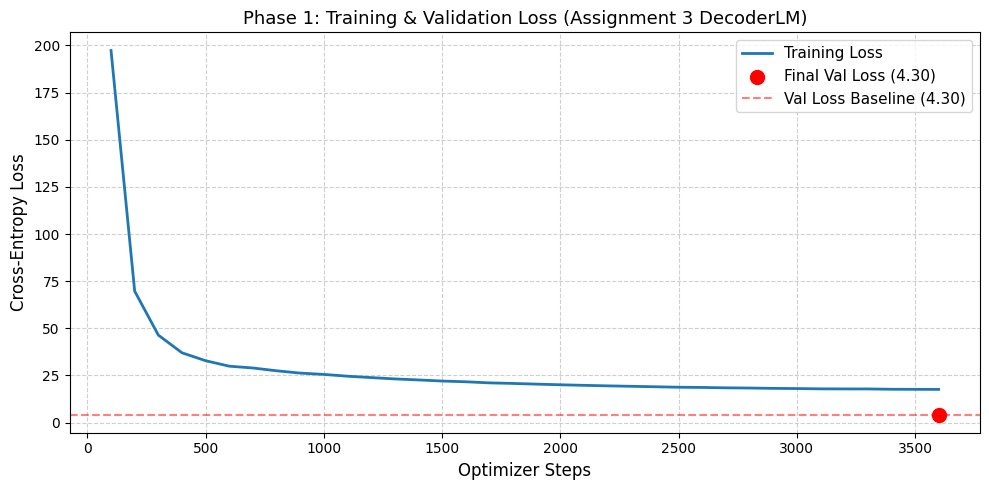

Loss plot saved to: /kaggle/working/cs781_phase1/training_validation_loss.png


In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Plot training loss curve
if train_steps:
    plt.plot(train_steps, train_loss, label="Training Loss", color="#1f77b4", linewidth=2)

# Plot validation loss evaluated at the end
if 'eval_loss' in locals() and train_steps:
    final_step = train_steps[-1]
    plt.scatter([final_step], [eval_loss], color="red", s=100, zorder=5, 
                label=f"Final Val Loss ({eval_loss:.2f})")
    plt.axhline(y=eval_loss, color="red", linestyle="--", alpha=0.5, 
                label=f"Val Loss Baseline ({eval_loss:.2f})")

plt.xlabel("Optimizer Steps", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.title("Phase 1: Training & Validation Loss (Assignment 3 DecoderLM)", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:", LOSS_PLOT_PATH)

## 16. Load Test Data from HuggingFace

In [ ]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

## 17. Load Test Prompts

In [ ]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

## 18. Generate 128 Words
#### (words, not tokens)

In [ ]:
def generate_128_words(prompt_text, model, tokenizer, device, target_words=128):
    tokens = tokenizer.encode(prompt_text)
    max_prompt = MODEL_SEQ_LEN - MAX_GENERATION_TOKENS
    if len(tokens) > max_prompt:
        tokens = tokens[-max_prompt:]
    prompt_len = len(tokens)
    full_tokens = model.generate(
        prompt_tokens=tokens,
        max_new_tokens=MAX_GENERATION_TOKENS,
        min_new_tokens=MIN_GENERATION_TOKENS,
        temperature=TEMPERATURE,
        top_p=TOP_P,
        repetition_penalty=REPETITION_PENALTY,
        device=device
    )
    gen_tokens = full_tokens[prompt_len:]
    gen_text = tokenizer.decode(gen_tokens).strip()
    # Enforce target sequence length
    words = gen_text.split()
    if len(words) >= target_words:
        continuation = " ".join(words[:target_words])
    else:
        continuation = " ".join(words)
    return continuation

## 20. Generate Predictions for the Test Set

In [ ]:
predictions = {}
items = list(test_data.items())
total = len(items)
print(f"Generating 128-word continuations for {total} test prompts...")
for idx, (ex_id, rec) in enumerate(items):
    continuation = generate_128_words(rec["text"], model, tokenizer, device, target_words=TARGET_GENERATION_WORDS)
    predictions[str(ex_id)] = {"text": continuation}
    if (idx + 1) % 50 == 0 or (idx + 1) == total:
        print(f"Progress: {idx + 1}/{total} ({(idx + 1)/total*100:.1f}%)")
print("Inference completed!")

## 21. Save prediction.json

In [ ]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

if os.path.exists(SUBMISSION_ZIP):
    os.remove(SUBMISSION_ZIP)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

## 22. Create CodaBench Submission ZIP

In [ ]:
with zipfile.ZipFile(SUBMISSION_ZIP, "r") as zipf:
    contents = zipf.namelist()
    print("Archive contents:", contents)
    assert contents == ["prediction.json"], "ERROR: Archive must contain ONLY prediction.json at root!"
print("\nSUCCESS! /kaggle/working/submission.zip is ready for Codabench submission.")